# 04 · FPCA univariado por indicador

**Fase del plan:** F4 – FPCA univariado.

**Objetivo:** para cada indicador, descomponer las curvas suavizadas de los 200 países en sus modos principales de variación (autofunciones). Se cuantifica cuánta variabilidad explica cada modo (FVE) y se interpretan los dos primeros, por ejemplo como diferencias de nivel o de *timing*. Los resultados sirven de insumo para el MFPCA (F5) y para la pregunta 8.

**Entradas:** `output/data/fd_1950_2023.rds` (objetos `fd` suavizados en F3), `output/data/meta_paises.rds`, `output/data/config.rds`.

**Salidas:**
- `output/data/fpca_<indicador>.rds`: scores país × componente (con `ISO3_code`, `Location` y región), valores propios, FVE, autofunciones y media.
- `output/tables/fpca_fve_<indicador>.csv`, `output/tables/fpca_resumen.csv|.tex`.
- Figuras `output/figures/fpca_<indicador>_autofunciones|perturbaciones` y `fpca_spearman_FPC1`.


## Configuración
`fda` se carga antes que `tidyverse`, porque `fda` carga MASS y este enmascara `dplyr::select`.


In [1]:
suppressPackageStartupMessages({
  library(fda)
  library(tidyverse)
  library(patchwork)
  library(here)
})
cfg <- readRDS(here::here("output/data/config.rds")); invisible(list2env(cfg, envir = globalenv())); set.seed(SEED)
options(repr.plot.width = 12, repr.plot.height = 7, repr.plot.res = 120, width = 150)
stopifnot(identical(select, dplyr::select))

meta_paises <- readRDS(here::here("output/data/meta_paises.rds"))
meta <- meta_paises |> filter(!es_pequeno)
fds  <- readRDS(here::here("output/data/fd_1950_2023.rds"))
IND  <- replace(IND_AMPLIADO, IND_AMPLIADO == "CNMR", "CNMR_t")
CAPTION <- "Fuente: UN WPP 2024"
T_FINO  <- seq(HORIZONTE[1], HORIZONTE[2], by = 0.25)
NHARM   <- 10

stopifnot(identical(names(fds), IND),
          all(sapply(fds, \(f) identical(colnames(f$fd$coefs), meta$ISO3_code))),
          all(sapply(fds, \(f) all(f$fd$basis$rangeval == HORIZONTE))))

ETIQ <- c(TFR = "Tasa global de fecundidad (hijos por mujer)", LEx = "Esperanza de vida al nacer (años)",
          CNMR_t = "asinh(tasa neta de migración por 1,000)", MAC = "Edad media a la maternidad (años)",
          MedianAgePop = "Edad mediana de la población (años)")
cat("Indicadores:", IND, "| países:", ncol(fds$TFR$fd$coefs), "| funciones base:", nrow(fds$TFR$fd$coefs), "\n")


Indicadores: TFR LEx CNMR_t MAC MedianAgePop | países: 200 | funciones base: 76 


## Método: FPCA centrado con `fda::pca.fd`

Para un indicador, sea $X_i(t)$ la curva suavizada del país $i$, con media $\hat\mu(t)=\frac1n\sum_i X_i(t)$ y covarianza
$$
\hat C(s,t)=\frac1n\sum_{i=1}^n\big(X_i(s)-\hat\mu(s)\big)\big(X_i(t)-\hat\mu(t)\big).
$$
El FPCA resuelve $\int \hat C(s,t)\,\hat\phi_r(s)\,ds=\hat\lambda_r\hat\phi_r(t)$, con $\|\hat\phi_r\|_{L^2}=1$ y $\hat\phi_r\perp\hat\phi_{r'}$, y da la expansión de Karhunen–Loève truncada
$$
X_i(t)\approx\hat\mu(t)+\sum_{r=1}^{K}\hat\xi_{ir}\hat\phi_r(t),\qquad \hat\xi_{ir}=\int\big(X_i(t)-\hat\mu(t)\big)\hat\phi_r(t)\,dt .
$$
La fracción de varianza explicada es $\mathrm{FVE}(K)=\sum_{r\le K}\hat\lambda_r/\sum_r\hat\lambda_r$, y $K_{90}$, $K_{95}$ son los menores $K$ con $\mathrm{FVE}(K)\ge 0.90$ y $\ge 0.95$.

**Por qué `pca.fd` sobre el objeto `fd`:**
- **Trabaja en la base suavizada de F3.** La covarianza se calcula exactamente sobre la representación B-spline de cada curva, sin discretizar, y respeta el $\lambda$ elegido por GCV. Las integrales usan la matriz de Gram de la base, así que el producto interno es el de $L^2$ y no el euclídeo de los vectores anuales.
- **Las curvas están completas y en una rejilla común**, así que no hace falta un FPCA para datos dispersos (PACE/`fdapace`).
- **Centrado (`centerfns = TRUE`):** se analiza la variación *entre países* alrededor de la media global, que es lo que interesa para agruparlos.
- **Sin penalización adicional en las armónicas:** se usa el `fdPar` por defecto, con $\lambda=0$. La suavidad ya se impuso en F3, y penalizar otra vez sesgaría las autofunciones.
- **`nharm = 10`:** basta de sobra para alcanzar el 95 % en indicadores suaves y permite ver la cola del espectro. $K_{90}$ y $K_{95}$ se calculan con los 76 valores propios, no solo con los 10 primeros.
- **Sin normalizar:** cada indicador está en su propia escala. La normalización de Chiou solo hace falta al combinar indicadores en el MFPCA (F5).

**Signo de las autofunciones.** El signo de $\hat\phi_r$ es arbitrario. Se fija para que $\int\hat\phi_r(t)\,dt>0$; así un score positivo significa "por encima de la media en promedio a lo largo del período" en la dirección de esa componente, y los scores cambian de signo junto con las autofunciones.


In [2]:
correr_fpca <- function(fdobj, nharm = NHARM) {
  p <- pca.fd(fdobj, nharm = nharm, centerfns = TRUE)
  # Convención de signo: integral de cada autofunción positiva
  integ <- colSums(eval.fd(T_FINO, p$harmonics)) * diff(T_FINO)[1]
  sgn <- ifelse(integ < 0, -1, 1)
  p$harmonics$coefs <- sweep(p$harmonics$coefs, 2, sgn, `*`)
  p$scores <- sweep(p$scores, 2, sgn, `*`)
  colnames(p$scores) <- paste0("FPC", seq_len(nharm))
  rownames(p$scores) <- colnames(fdobj$coefs)
  # Verificaciones: ortonormalidad y reconstrucción con 10 componentes
  G <- inprod(p$harmonics, p$harmonics)
  stopifnot(max(abs(G - diag(nharm))) < 1e-3,   # tolerancia por la cuadratura numérica de inprod
            all(diff(p$values) <= 1e-10), abs(sum(p$varprop) - sum(p$values[1:nharm]) / sum(p$values)) < 1e-12)
  p
}

tabla_fve <- function(p, ind) {
  fve <- p$values / sum(p$values)
  tibble(indicador = ind, componente = paste0("FPC", 1:NHARM), valor_propio = p$values[1:NHARM],
         FVE = fve[1:NHARM], FVE_acum = cumsum(fve)[1:NHARM])
}
K_fve <- function(p, umbral) which(cumsum(p$values) / sum(p$values) >= umbral)[1]

fig_autofunciones <- function(p, ind, r = 1:3) {
  fve <- p$values / sum(p$values)
  d <- as_tibble(eval.fd(T_FINO, p$harmonics)[, r, drop = FALSE], .name_repair = ~ paste0("FPC", r)) |>
    mutate(Time = T_FINO) |> pivot_longer(-Time, names_to = "comp") |>
    mutate(comp = factor(comp, levels = paste0("FPC", r),
                         labels = sprintf("FPC%d (FVE = %.1f %%)", r, 100 * fve[r])))
  ggplot(d, aes(Time, value, colour = comp)) +
    geom_hline(yintercept = 0, colour = "grey60") +
    geom_line(linewidth = 1.1) +
    scale_colour_manual(values = c("#0072B2", "#D55E00", "#009E73"), name = NULL) +
    labs(title = paste0(ind, ": tres primeras autofunciones"),
         subtitle = "Signo fijado con integral positiva",
         x = "Año", y = expression(hat(phi)[r](t)), caption = CAPTION) +
    theme_minimal(base_size = 11) + theme(legend.position = "bottom")
}

fig_perturbaciones <- function(p, ind, r = 1:3) {
  fve <- p$values / sum(p$values)
  mu  <- as.vector(eval.fd(T_FINO, p$meanfd))
  phi <- eval.fd(T_FINO, p$harmonics)
  d <- map_dfr(r, function(k) {
    a <- 2 * sqrt(p$values[k])
    tibble(Time = T_FINO, media = mu, mas = mu + a * phi[, k], menos = mu - a * phi[, k],
           comp = sprintf("FPC%d · FVE = %.1f %%", k, 100 * fve[k]))
  }) |> mutate(comp = factor(comp, levels = unique(comp)))
  ggplot(d, aes(Time)) +
    geom_line(aes(y = media, linetype = "Media"), colour = "black", linewidth = 1) +
    geom_line(aes(y = mas, colour = "+2 sd"), linewidth = 0.9) +
    geom_line(aes(y = menos, colour = "-2 sd"), linewidth = 0.9) +
    facet_wrap(~ comp, ncol = 1, scales = "free_y") +
    scale_colour_manual(values = c("+2 sd" = "#D55E00", "-2 sd" = "#0072B2"), name = NULL) +
    scale_linetype_manual(values = c("Media" = "solid"), name = NULL) +
    labs(title = paste0(ind, ": perturbaciones de la media"),
         subtitle = expression(hat(mu)(t) %+-% 2 * sqrt(hat(lambda)[r]) * hat(phi)[r](t)),
         x = "Año", y = ETIQ[[ind]], caption = CAPTION) +
    theme_minimal(base_size = 11) + theme(legend.position = "bottom")
}

tabla_scores <- function(p) {
  as_tibble(p$scores, rownames = "ISO3_code") |>
    left_join(meta |> select(ISO3_code, Location, region), by = "ISO3_code") |>
    relocate(Location, region, .after = ISO3_code)
}

# Países extremos en FPC1 y FPC2 (para interpretar)
extremos <- function(sc, comp, n = 5) {
  o <- order(sc[[comp]])
  cat(sprintf("%s  más negativos: %s\n", comp, paste(sc$ISO3_code[head(o, n)], collapse = ", ")))
  cat(sprintf("%s  más positivos: %s\n", comp, paste(sc$ISO3_code[rev(tail(o, n))], collapse = ", ")))
}

resumen <- list(); fpc1 <- list()


# Indicador: TFR – Tasa global de fecundidad

## TFR · 1–2. FPCA y fracción de varianza explicada
FPCA centrado sobre el objeto `fd` de F3 (200 países, 76 funciones base) con `nharm = 10`. La tabla muestra los 10 primeros valores propios con su FVE individual y acumulado; $K_{90}$ y $K_{95}$ se calculan con el espectro completo.


In [3]:
p <- correr_fpca(fds[["TFR"]]$fd)
tab <- tabla_fve(p, "TFR")
guardar_tabla(tab, "fpca_fve_TFR")
tab |> mutate(valor_propio = signif(valor_propio, 4), across(c(FVE, FVE_acum), ~ round(100 * .x, 2))) |>
  rename(`FVE (%)` = FVE, `FVE acum (%)` = FVE_acum) |> as.data.frame() |> print(row.names = FALSE)
K90 <- K_fve(p, 0.90); K95 <- K_fve(p, 0.95)
cat(sprintf("\nK90 = %d | K95 = %d\n", K90, K95))


 indicador componente valor_propio FVE (%) FVE acum (%)
       TFR       FPC1    190.10000   85.14        85.14
       TFR       FPC2     24.78000   11.10        96.24
       TFR       FPC3      4.66400    2.09        98.33
       TFR       FPC4      1.76300    0.79        99.12
       TFR       FPC5      0.74290    0.33        99.45
       TFR       FPC6      0.42020    0.19        99.64
       TFR       FPC7      0.21710    0.10        99.74
       TFR       FPC8      0.15640    0.07        99.81
       TFR       FPC9      0.08719    0.04        99.85
       TFR      FPC10      0.08163    0.04        99.88

K90 = 2 | K95 = 2


## TFR · 3. Autofunciones y perturbaciones de la media
La primera figura muestra las tres primeras autofunciones $\hat\phi_r(t)$. La segunda muestra, para cada componente, la media $\hat\mu(t)$ (negro) y las curvas $\hat\mu(t)\pm2\sqrt{\hat\lambda_r}\,\hat\phi_r(t)$: cómo se ve un país con score de $\pm2$ desviaciones estándar en esa componente y 0 en las demás.


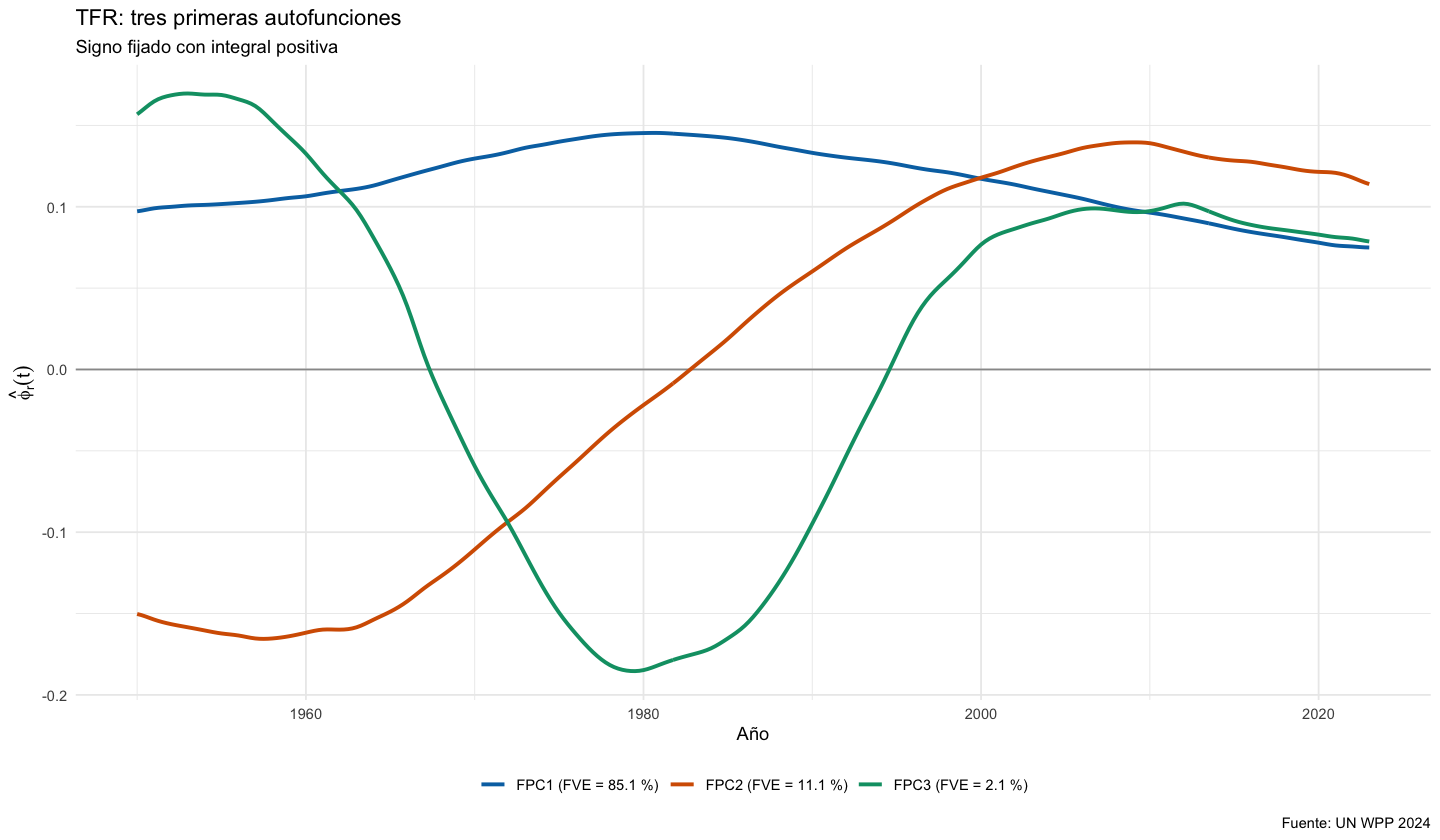

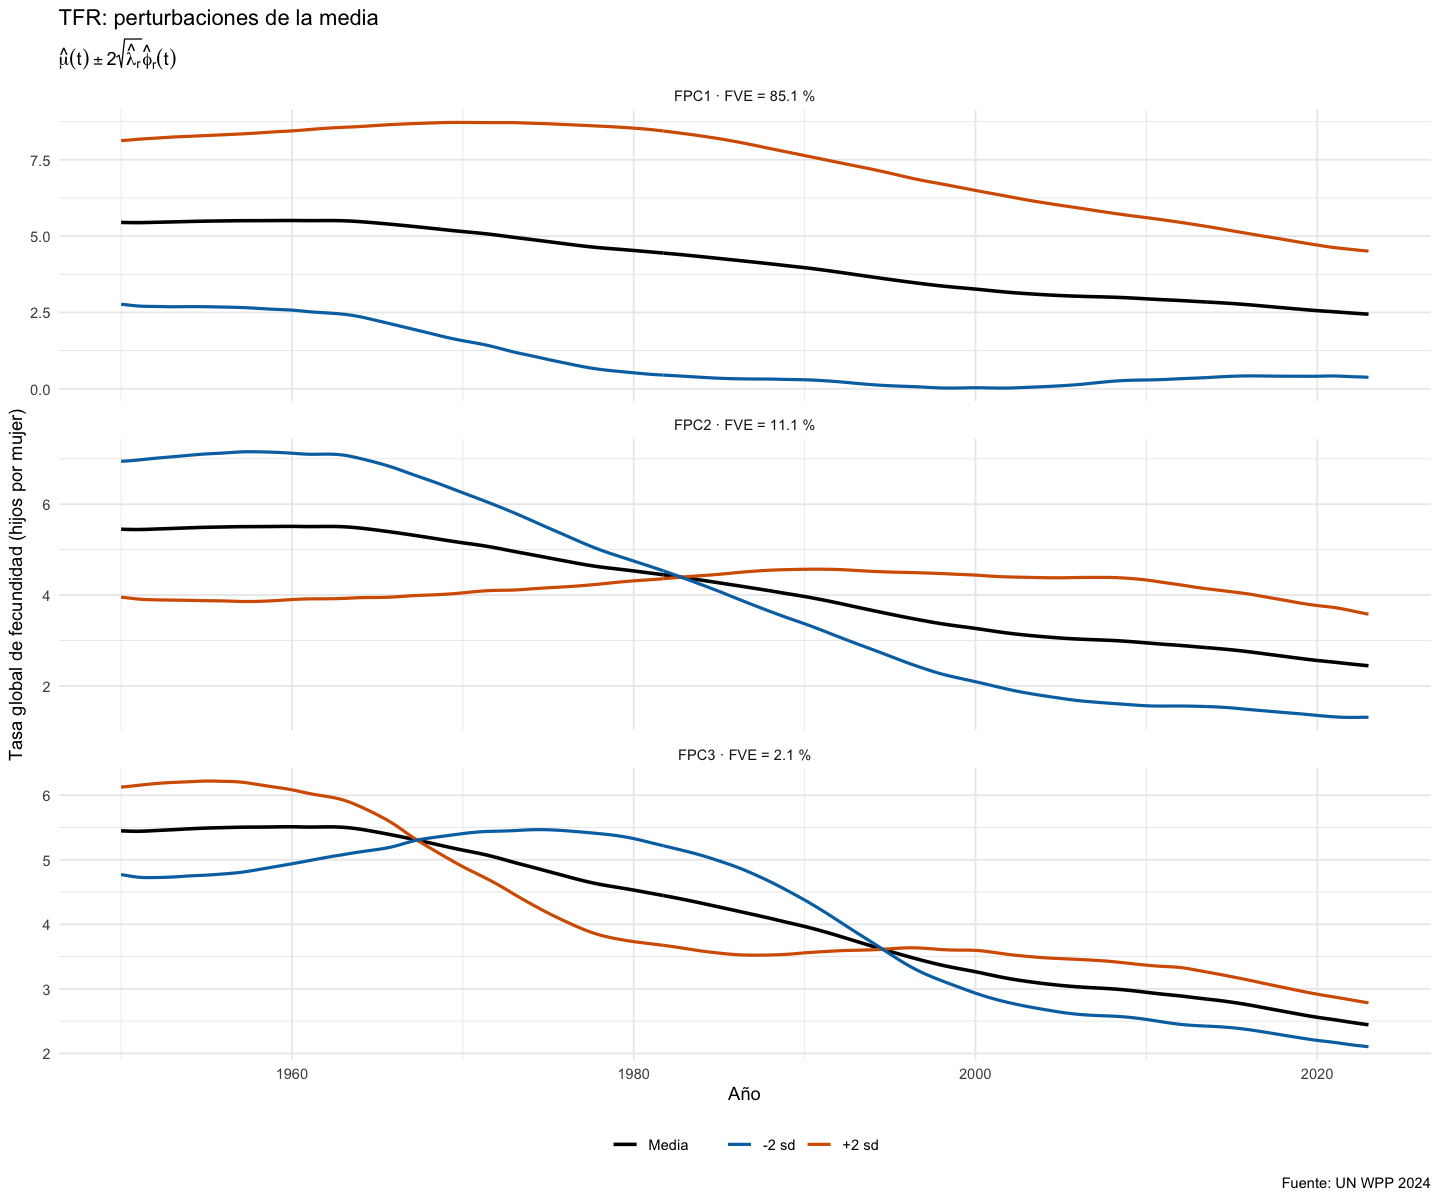

In [4]:
p1 <- fig_autofunciones(p, "TFR")
guardar_fig(p1, "fpca_TFR_autofunciones", w = 10, h = 5.5); print(p1)
options(repr.plot.height = 10)
p2 <- fig_perturbaciones(p, "TFR")
guardar_fig(p2, "fpca_TFR_perturbaciones", w = 9, h = 10); print(p2)
options(repr.plot.height = 7)


## TFR · 4. Scores
Se guardan los scores país × componente (FPC1–FPC10, con `ISO3_code`, `Location` y región) junto con los valores propios, las autofunciones y la media en `output/data/fpca_TFR.rds`. Se listan los cinco países con scores más extremos en FPC1 y FPC2 como apoyo a la interpretación.


In [5]:
sc <- tabla_scores(p)
stopifnot(nrow(sc) == 200, !anyNA(sc), abs(colMeans(p$scores)) < 1e-8 * max(abs(p$scores)))
saveRDS(list(indicador = "TFR", scores = sc, values = p$values, fve = p$values / sum(p$values),
             K90 = K90, K95 = K95, harmonics = p$harmonics, meanfd = p$meanfd, lambda_suav = fds[["TFR"]]$lambda),
        here::here("output/data/fpca_TFR.rds"))
extremos(sc, "FPC1"); extremos(sc, "FPC2")
sc |> group_by(region) |> summarise(n = n(), FPC1_media = mean(FPC1), FPC2_media = mean(FPC2), .groups = "drop") |>
  mutate(across(where(is.double), ~ round(.x, 2))) |> as.data.frame() |> print(row.names = FALSE)

fve <- p$values / sum(p$values)
resumen[["TFR"]] <- tibble(indicador = "TFR", FVE1 = fve[1], FVE2 = fve[2], FVE3 = fve[3], K90 = K90, K95 = K95)
fpc1[["TFR"]] <- setNames(sc$FPC1, sc$ISO3_code)


FPC1  más negativos: DEU, JEY, JPN, LUX, LVA
FPC1  más positivos: NER, YEM, SOM, AFG, MLI


FPC2  más negativos: IRN, VCT, LBY, TUN, KWT
FPC2  más positivos: TCD, COD, SOM, NER, CAF
                          region  n FPC1_media FPC2_media
                          Africa 57      13.77       2.40
                            Asia 51       1.12      -3.13
                          Europe 41     -17.80       3.45
 Latin America and the Caribbean 36      -2.91      -3.19
                Northern America  2     -17.09       2.81
                         Oceania 13       2.07      -0.71


## TFR · 5. Interpretación
- **FPC1 (85.1 %): nivel general de fecundidad.** La autofunción es positiva en todo el período, así que un score alto desplaza la curva entera hacia arriba (≈ +3 hijos con +2 sd). El desplazamiento es algo mayor después de 1980, que es cuando se abre la brecha entre países. En el extremo positivo están Níger, Yemen, Somalia, Afganistán y Malí (fecundidad alta y persistente); en el negativo, Alemania, Japón, Luxemburgo y Letonia (fecundidad baja ya en 1950). Por región, África tiene media +13.8 y Europa −17.8.
- **FPC2 (11.1 %): velocidad y *timing* de la transición.** La autofunción cambia de signo hacia 1983. Un score **negativo** describe una fecundidad *más alta* que la media hasta ~1983 y *más baja* después, es decir, una transición tardía en su inicio pero muy rápida (Irán, Libia, Túnez, Kuwait, San Vicente y las Granadinas). Un score **positivo** describe la forma opuesta: una curva casi plana, por debajo de la media al inicio y por encima al final, que corresponde a una transición lenta o detenida (Chad, RD del Congo, Somalia, Níger, República Centroafricana).
- Con $K_{90}=K_{95}=2$, TFR queda descrita casi por completo por *nivel* y *timing de la caída*. FPC3 (2.1 %) agrega un matiz: caída temprana con estancamiento posterior frente a meseta seguida de caída tardía.


# Indicador: LEx – Esperanza de vida al nacer

## LEx · 1–2. FPCA y fracción de varianza explicada
FPCA centrado sobre el objeto `fd` de F3 (200 países, 76 funciones base) con `nharm = 10`. La tabla muestra los 10 primeros valores propios con su FVE individual y acumulado; $K_{90}$ y $K_{95}$ se calculan con el espectro completo.


In [6]:
p <- correr_fpca(fds[["LEx"]]$fd)
tab <- tabla_fve(p, "LEx")
guardar_tabla(tab, "fpca_fve_LEx")
tab |> mutate(valor_propio = signif(valor_propio, 4), across(c(FVE, FVE_acum), ~ round(100 * .x, 2))) |>
  rename(`FVE (%)` = FVE, `FVE acum (%)` = FVE_acum) |> as.data.frame() |> print(row.names = FALSE)
K90 <- K_fve(p, 0.90); K95 <- K_fve(p, 0.95)
cat(sprintf("\nK90 = %d | K95 = %d\n", K90, K95))


 indicador componente valor_propio FVE (%) FVE acum (%)
       LEx       FPC1     6646.000   88.21        88.21
       LEx       FPC2      561.200    7.45        95.66
       LEx       FPC3      171.900    2.28        97.94
       LEx       FPC4       47.610    0.63        98.57
       LEx       FPC5       32.550    0.43        99.01
       LEx       FPC6       27.090    0.36        99.37
       LEx       FPC7       14.190    0.19        99.55
       LEx       FPC8        8.861    0.12        99.67
       LEx       FPC9        6.347    0.08        99.76
       LEx      FPC10        4.843    0.06        99.82

K90 = 2 | K95 = 2


## LEx · 3. Autofunciones y perturbaciones de la media
La primera figura muestra las tres primeras autofunciones $\hat\phi_r(t)$. La segunda muestra, para cada componente, la media $\hat\mu(t)$ (negro) y las curvas $\hat\mu(t)\pm2\sqrt{\hat\lambda_r}\,\hat\phi_r(t)$: cómo se ve un país con score de $\pm2$ desviaciones estándar en esa componente y 0 en las demás.


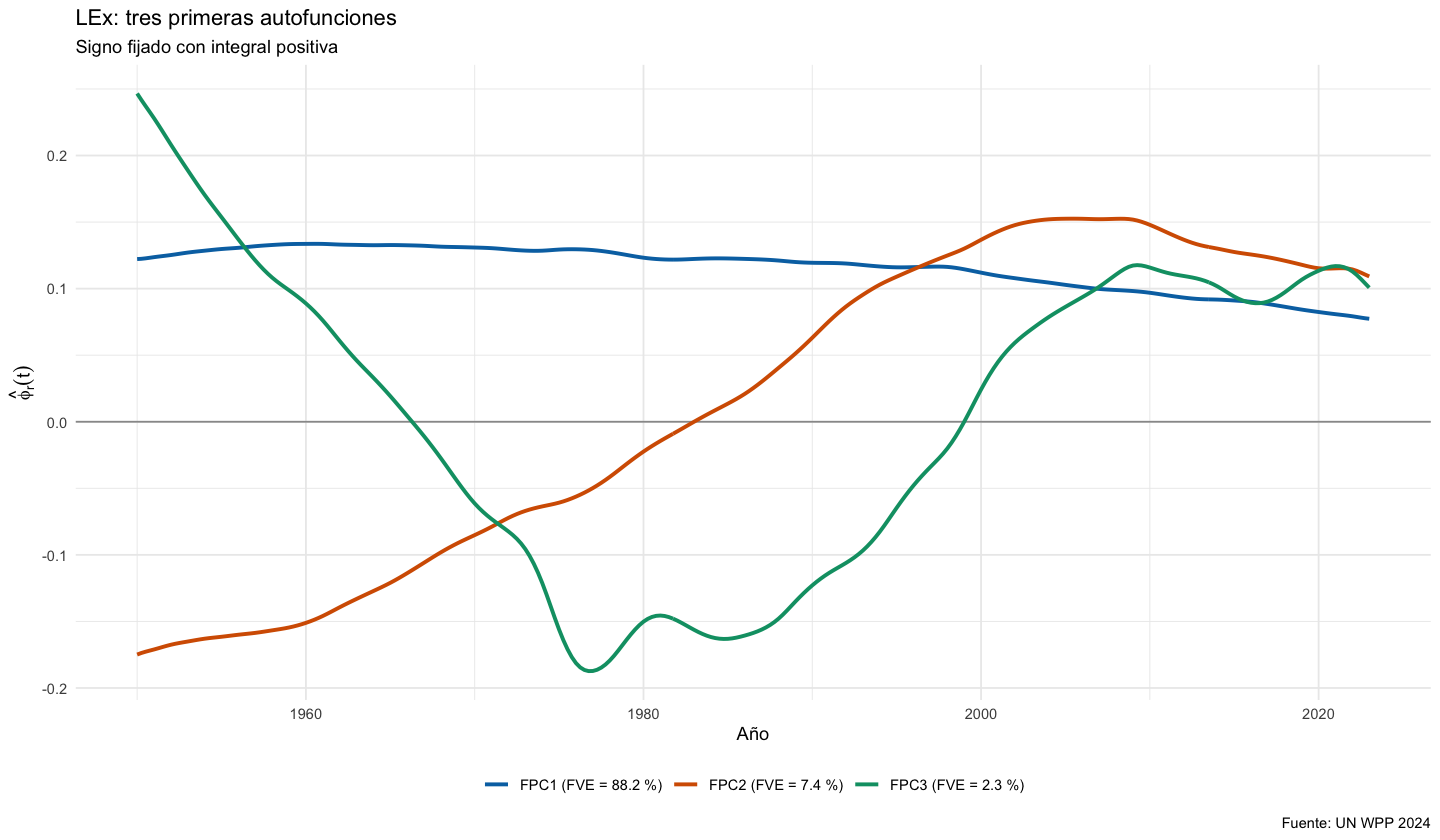

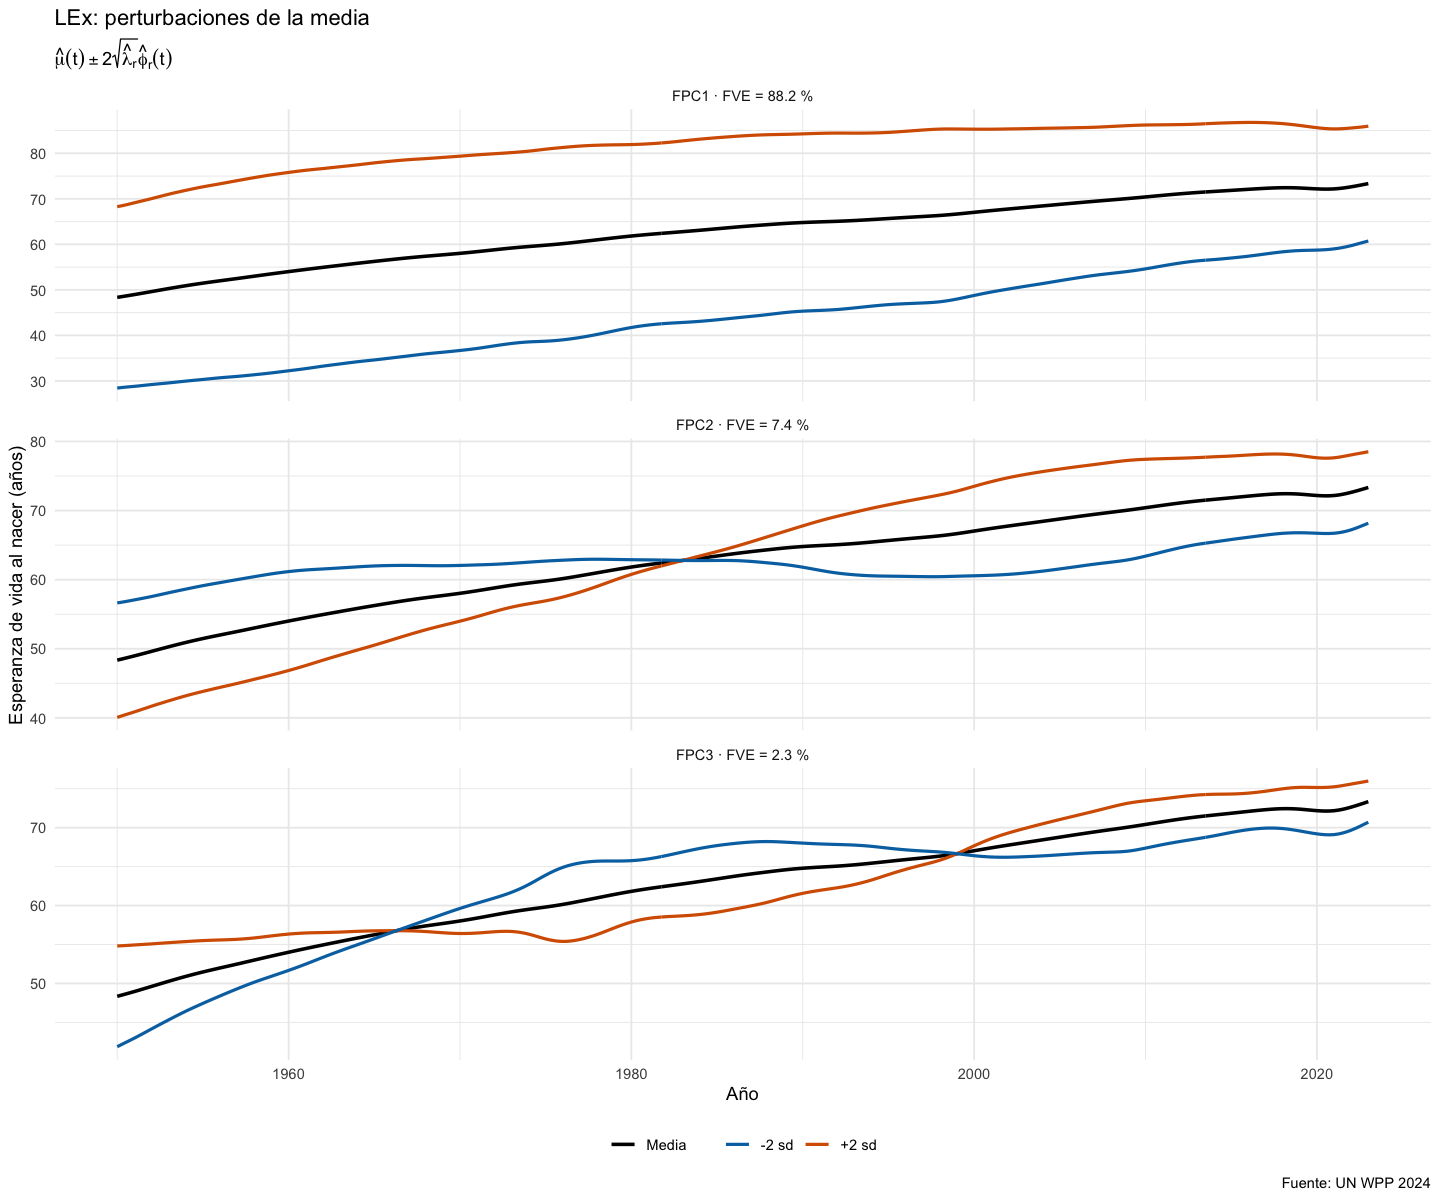

In [7]:
p1 <- fig_autofunciones(p, "LEx")
guardar_fig(p1, "fpca_LEx_autofunciones", w = 10, h = 5.5); print(p1)
options(repr.plot.height = 10)
p2 <- fig_perturbaciones(p, "LEx")
guardar_fig(p2, "fpca_LEx_perturbaciones", w = 9, h = 10); print(p2)
options(repr.plot.height = 7)


## LEx · 4. Scores
Se guardan los scores país × componente (FPC1–FPC10, con `ISO3_code`, `Location` y región) junto con los valores propios, las autofunciones y la media en `output/data/fpca_LEx.rds`. Se listan los cinco países con scores más extremos en FPC1 y FPC2 como apoyo a la interpretación.


In [8]:
sc <- tabla_scores(p)
stopifnot(nrow(sc) == 200, !anyNA(sc), abs(colMeans(p$scores)) < 1e-8 * max(abs(p$scores)))
saveRDS(list(indicador = "LEx", scores = sc, values = p$values, fve = p$values / sum(p$values),
             K90 = K90, K95 = K95, harmonics = p$harmonics, meanfd = p$meanfd, lambda_suav = fds[["LEx"]]$lambda),
        here::here("output/data/fpca_LEx.rds"))
extremos(sc, "FPC1"); extremos(sc, "FPC2")
sc |> group_by(region) |> summarise(n = n(), FPC1_media = mean(FPC1), FPC2_media = mean(FPC2), .groups = "drop") |>
  mutate(across(where(is.double), ~ round(.x, 2))) |> as.data.frame() |> print(row.names = FALSE)

fve <- p$values / sum(p$values)
resumen[["LEx"]] <- tibble(indicador = "LEx", FVE1 = fve[1], FVE2 = fve[2], FVE3 = fve[3], K90 = K90, K95 = K95)
fpc1[["LEx"]] <- setNames(sc$FPC1, sc$ISO3_code)


FPC1  más negativos: SSD, SLE, MLI, TLS, NER
FPC1  más positivos: ISL, SWE, NOR, CHE, NLD
FPC2  más negativos: ZWE, LSO, ZMB, CAF, SWZ
FPC2  más positivos: OMN, MDV, DZA, KOR, SAU
                          region  n FPC1_media FPC2_media
                          Africa 57     -88.19      -7.74
                            Asia 51      -0.23      16.84
                          Europe 41      85.04     -12.46
 Latin America and the Caribbean 36      28.83       2.86
                Northern America  2     107.87     -12.25
                         Oceania 13      22.99       1.14


## LEx · 5. Interpretación
- **FPC1 (88.2 %): nivel general de esperanza de vida.** La autofunción es positiva en todo el período y más grande al inicio. Con +2 sd, la curva queda ~20 años sobre la media en 1950 y ~13 en 2023, lo que refleja la convergencia vista en F2. En el extremo positivo están Islandia, Suecia, Noruega, Suiza y Países Bajos; en el negativo, Sudán del Sur, Sierra Leona, Malí, Timor-Leste y Níger. Por región, Europa tiene media +85 y África −88.
- **FPC2 (7.4 %): velocidad de la ganancia y estancamiento.** La autofunción cambia de signo hacia 1983.
  - Un score **positivo** describe un país que parte bajo y gana años de forma rápida y sostenida, hasta quedar por encima de la media desde los 80: Omán, Maldivas, Argelia, Corea del Sur y Arabia Saudita. Es la "convergencia acelerada" típica de Asia (media de la región: +16.8).
  - Un score **negativo** describe ganancias tempranas seguidas de un **estancamiento o retroceso entre 1985 y 2005**: Zimbabue, Lesoto, Zambia, Esuatini y República Centroafricana. Es la firma del VIH/sida en África austral. Europa también tiene media negativa (−12.5): partió alto y ganó más despacio, con el estancamiento postsoviético.
- FPC3 (2.3 %) recoge una meseta en los años 70 y 80, seguida de una recuperación, frente a un avance temprano.
- Con $K_{90}=K_{95}=2$, LEx también queda descrita por *nivel* y *velocidad/estancamiento*.


# Indicador: CNMR_t – Tasa neta de migración transformada (asinh)

## CNMR_t · 1–2. FPCA y fracción de varianza explicada
FPCA centrado sobre el objeto `fd` de F3 (200 países, 76 funciones base) con `nharm = 10`. La tabla muestra los 10 primeros valores propios con su FVE individual y acumulado; $K_{90}$ y $K_{95}$ se calculan con el espectro completo.


In [9]:
p <- correr_fpca(fds[["CNMR_t"]]$fd)
tab <- tabla_fve(p, "CNMR_t")
guardar_tabla(tab, "fpca_fve_CNMR_t")
tab |> mutate(valor_propio = signif(valor_propio, 4), across(c(FVE, FVE_acum), ~ round(100 * .x, 2))) |>
  rename(`FVE (%)` = FVE, `FVE acum (%)` = FVE_acum) |> as.data.frame() |> print(row.names = FALSE)
K90 <- K_fve(p, 0.90); K95 <- K_fve(p, 0.95)
cat(sprintf("\nK90 = %d | K95 = %d\n", K90, K95))


 indicador componente valor_propio FVE (%) FVE acum (%)
    CNMR_t       FPC1      142.000   47.62        47.62
    CNMR_t       FPC2       51.690   17.33        64.95
    CNMR_t       FPC3       22.530    7.55        72.50
    CNMR_t       FPC4       18.170    6.09        78.60
    CNMR_t       FPC5       13.110    4.40        83.00
    CNMR_t       FPC6        9.730    3.26        86.26
    CNMR_t       FPC7        8.281    2.78        89.04
    CNMR_t       FPC8        6.486    2.18        91.21
    CNMR_t       FPC9        4.371    1.47        92.68
    CNMR_t      FPC10        4.078    1.37        94.04

K90 = 8 | K95 = 11


## CNMR_t · 3. Autofunciones y perturbaciones de la media
La primera figura muestra las tres primeras autofunciones $\hat\phi_r(t)$. La segunda muestra, para cada componente, la media $\hat\mu(t)$ (negro) y las curvas $\hat\mu(t)\pm2\sqrt{\hat\lambda_r}\,\hat\phi_r(t)$: cómo se ve un país con score de $\pm2$ desviaciones estándar en esa componente y 0 en las demás.


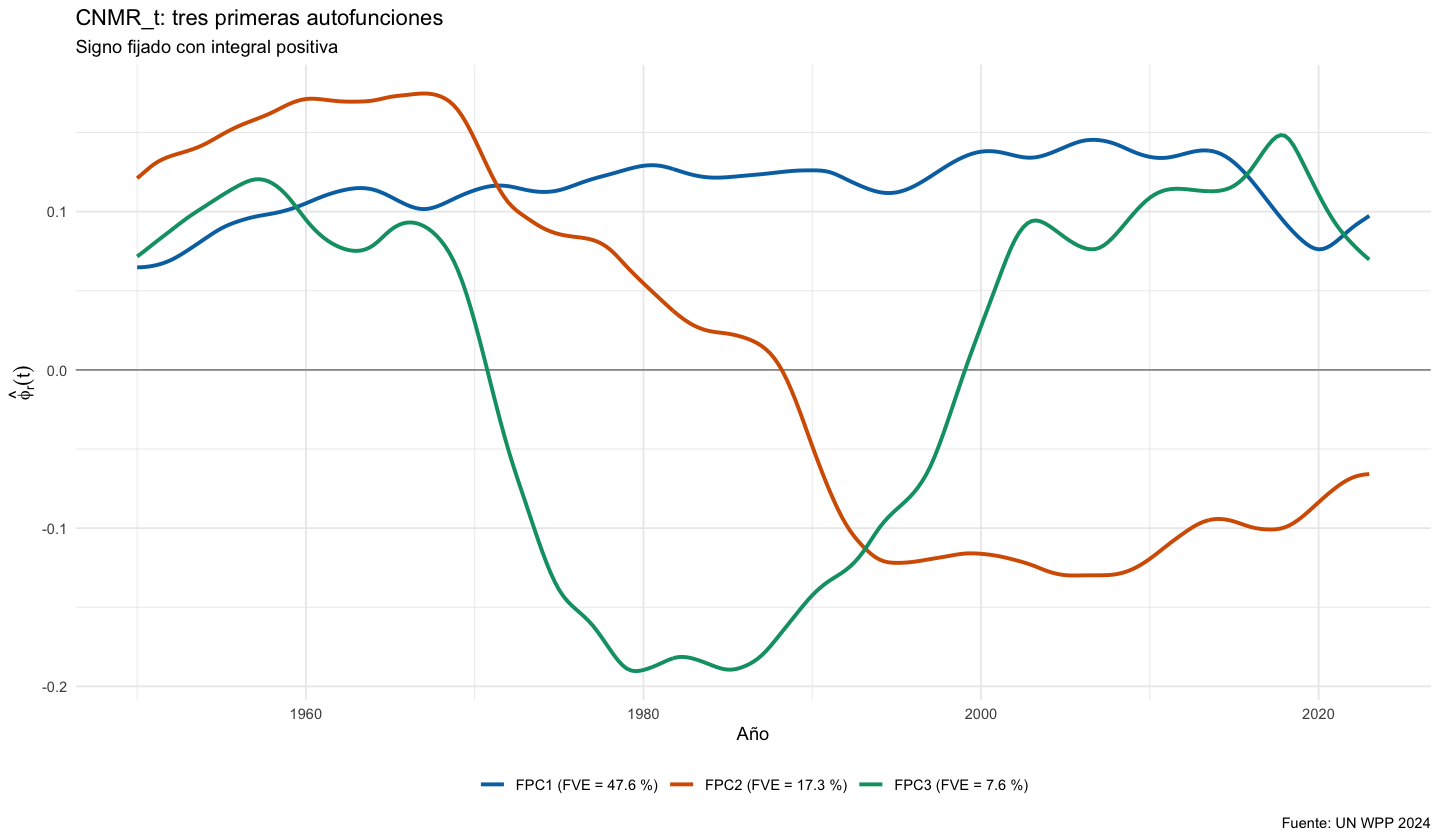

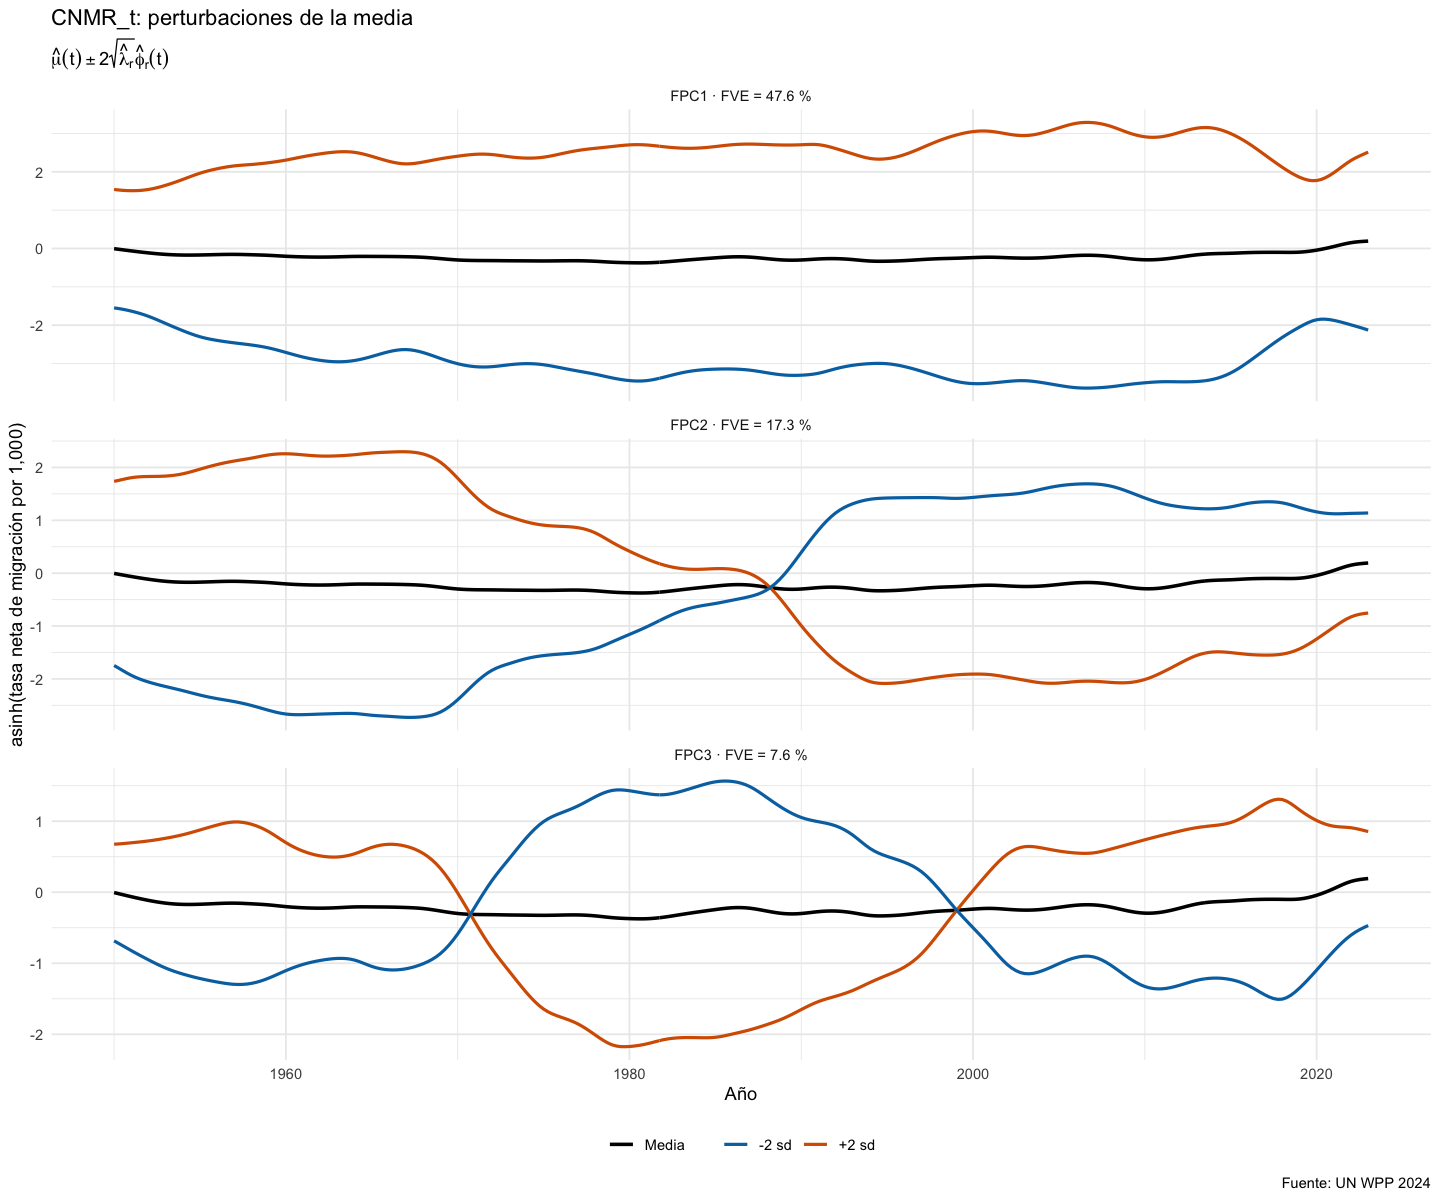

In [10]:
p1 <- fig_autofunciones(p, "CNMR_t")
guardar_fig(p1, "fpca_CNMR_t_autofunciones", w = 10, h = 5.5); print(p1)
options(repr.plot.height = 10)
p2 <- fig_perturbaciones(p, "CNMR_t")
guardar_fig(p2, "fpca_CNMR_t_perturbaciones", w = 9, h = 10); print(p2)
options(repr.plot.height = 7)


## CNMR_t · 4. Scores
Se guardan los scores país × componente (FPC1–FPC10, con `ISO3_code`, `Location` y región) junto con los valores propios, las autofunciones y la media en `output/data/fpca_CNMR_t.rds`. Se listan los cinco países con scores más extremos en FPC1 y FPC2 como apoyo a la interpretación.


In [11]:
sc <- tabla_scores(p)
stopifnot(nrow(sc) == 200, !anyNA(sc), abs(colMeans(p$scores)) < 1e-8 * max(abs(p$scores)))
saveRDS(list(indicador = "CNMR_t", scores = sc, values = p$values, fve = p$values / sum(p$values),
             K90 = K90, K95 = K95, harmonics = p$harmonics, meanfd = p$meanfd, lambda_suav = fds[["CNMR_t"]]$lambda),
        here::here("output/data/fpca_CNMR_t.rds"))
extremos(sc, "FPC1"); extremos(sc, "FPC2")
sc |> group_by(region) |> summarise(n = n(), FPC1_media = mean(FPC1), FPC2_media = mean(FPC2), .groups = "drop") |>
  mutate(across(where(is.double), ~ round(.x, 2))) |> as.data.frame() |> print(row.names = FALSE)

fve <- p$values / sum(p$values)
resumen[["CNMR_t"]] <- tibble(indicador = "CNMR_t", FVE1 = fve[1], FVE2 = fve[2], FVE3 = fve[3], K90 = K90, K95 = K95)
fpc1[["CNMR_t"]] <- setNames(sc$FPC1, sc$ISO3_code)


FPC1  más negativos: WSM, TON, VCT, GRD, GUY
FPC1  más positivos: ARE, QAT, ESH, KWT, SAU
FPC2  más negativos: ABW, MLT, PNG, MAC, MYS
FPC2  más positivos: ARM, ALB, LVA, MDA, KAZ
                          region  n FPC1_media FPC2_media
                          Africa 57      -0.89      -0.13
                            Asia 51       5.07       2.06
                          Europe 41       3.48      -0.94
 Latin America and the Caribbean 36      -8.18      -2.10
                Northern America  2      19.79      -0.47
                         Oceania 13      -7.36       1.32


## CNMR_t · 5. Interpretación
- **FPC1 (47.6 %): signo y nivel de la migración neta (receptor frente a emisor).** La autofunción es positiva y casi constante, así que un score alto describe un receptor neto persistente. En el extremo positivo están EAU, Qatar, Sahara Occidental, Kuwait y Arabia Saudita (Northern America tiene media +19.8). En el extremo negativo, Samoa, Tonga, San Vicente, Granada y Guyana: emisores crónicos del Pacífico y el Caribe (las medias de América Latina y Oceanía son −8.2 y −7.4).
- **FPC2 (17.3 %): reversión del régimen migratorio hacia 1988–1990.**
  - Un score **positivo** describe un receptor (o estable) hasta ~1970 que se vuelve **emisor neto desde 1990**: Armenia, Albania, Letonia, Moldavia y Kazajistán. Es la firma del colapso del bloque soviético.
  - Un score **negativo** describe la transición opuesta, de emisor a receptor: Aruba, Malta, Macao y Malasia.
- **FPC3 (7.6 %):** contrasta 1975–1995 con el resto del período, es decir, episodios migratorios de duración intermedia.
- **El espectro es mucho más plano que en TFR o LEx:** $K_{90}=8$ y $K_{95}=11$ (con 10 componentes se llega al 94.0 %). La migración tiene muchos modos de variación de importancia parecida (episodios concretos en distintos momentos), así que en el MFPCA aportará varias componentes de baja varianza. Además, con $K_{95}>10$, los scores guardados (FPC1–FPC10) no alcanzan el 95 % para este indicador.


# Indicador: MAC – Edad media a la maternidad

## MAC · 1–2. FPCA y fracción de varianza explicada
FPCA centrado sobre el objeto `fd` de F3 (200 países, 76 funciones base) con `nharm = 10`. La tabla muestra los 10 primeros valores propios con su FVE individual y acumulado; $K_{90}$ y $K_{95}$ se calculan con el espectro completo.


In [12]:
p <- correr_fpca(fds[["MAC"]]$fd)
tab <- tabla_fve(p, "MAC")
guardar_tabla(tab, "fpca_fve_MAC")
tab |> mutate(valor_propio = signif(valor_propio, 4), across(c(FVE, FVE_acum), ~ round(100 * .x, 2))) |>
  rename(`FVE (%)` = FVE, `FVE acum (%)` = FVE_acum) |> as.data.frame() |> print(row.names = FALSE)
K90 <- K_fve(p, 0.90); K95 <- K_fve(p, 0.95)
cat(sprintf("\nK90 = %d | K95 = %d\n", K90, K95))


 indicador componente valor_propio FVE (%) FVE acum (%)
       MAC       FPC1     91.02000   63.09        63.09
       MAC       FPC2     38.65000   26.79        89.88
       MAC       FPC3     10.89000    7.55        97.43
       MAC       FPC4      1.37100    0.95        98.38
       MAC       FPC5      0.81710    0.57        98.94
       MAC       FPC6      0.65700    0.46        99.40
       MAC       FPC7      0.25160    0.17        99.57
       MAC       FPC8      0.18030    0.12        99.70
       MAC       FPC9      0.11050    0.08        99.77
       MAC      FPC10      0.06399    0.04        99.82

K90 = 3 | K95 = 3


## MAC · 3. Autofunciones y perturbaciones de la media
La primera figura muestra las tres primeras autofunciones $\hat\phi_r(t)$. La segunda muestra, para cada componente, la media $\hat\mu(t)$ (negro) y las curvas $\hat\mu(t)\pm2\sqrt{\hat\lambda_r}\,\hat\phi_r(t)$: cómo se ve un país con score de $\pm2$ desviaciones estándar en esa componente y 0 en las demás.


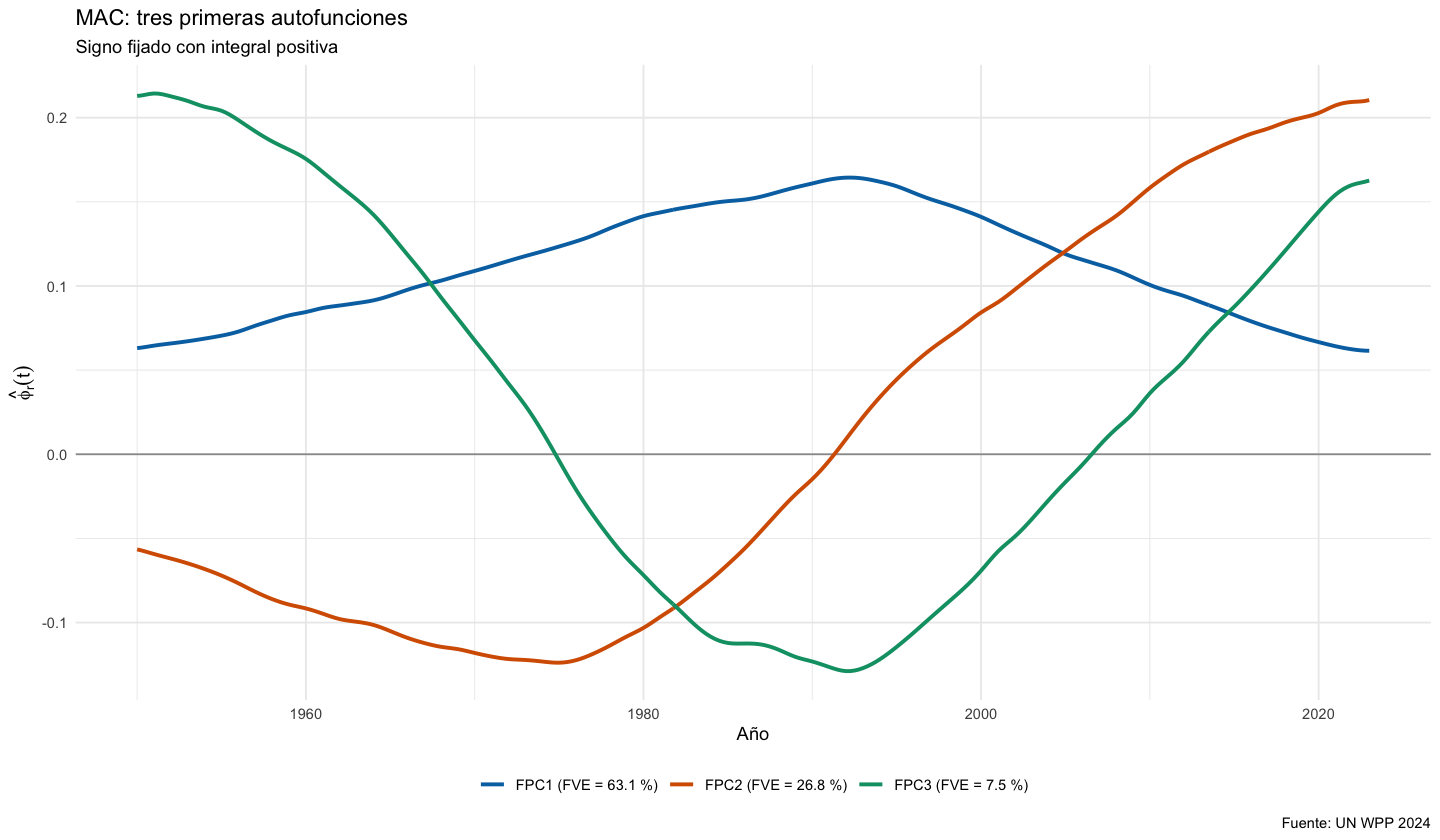

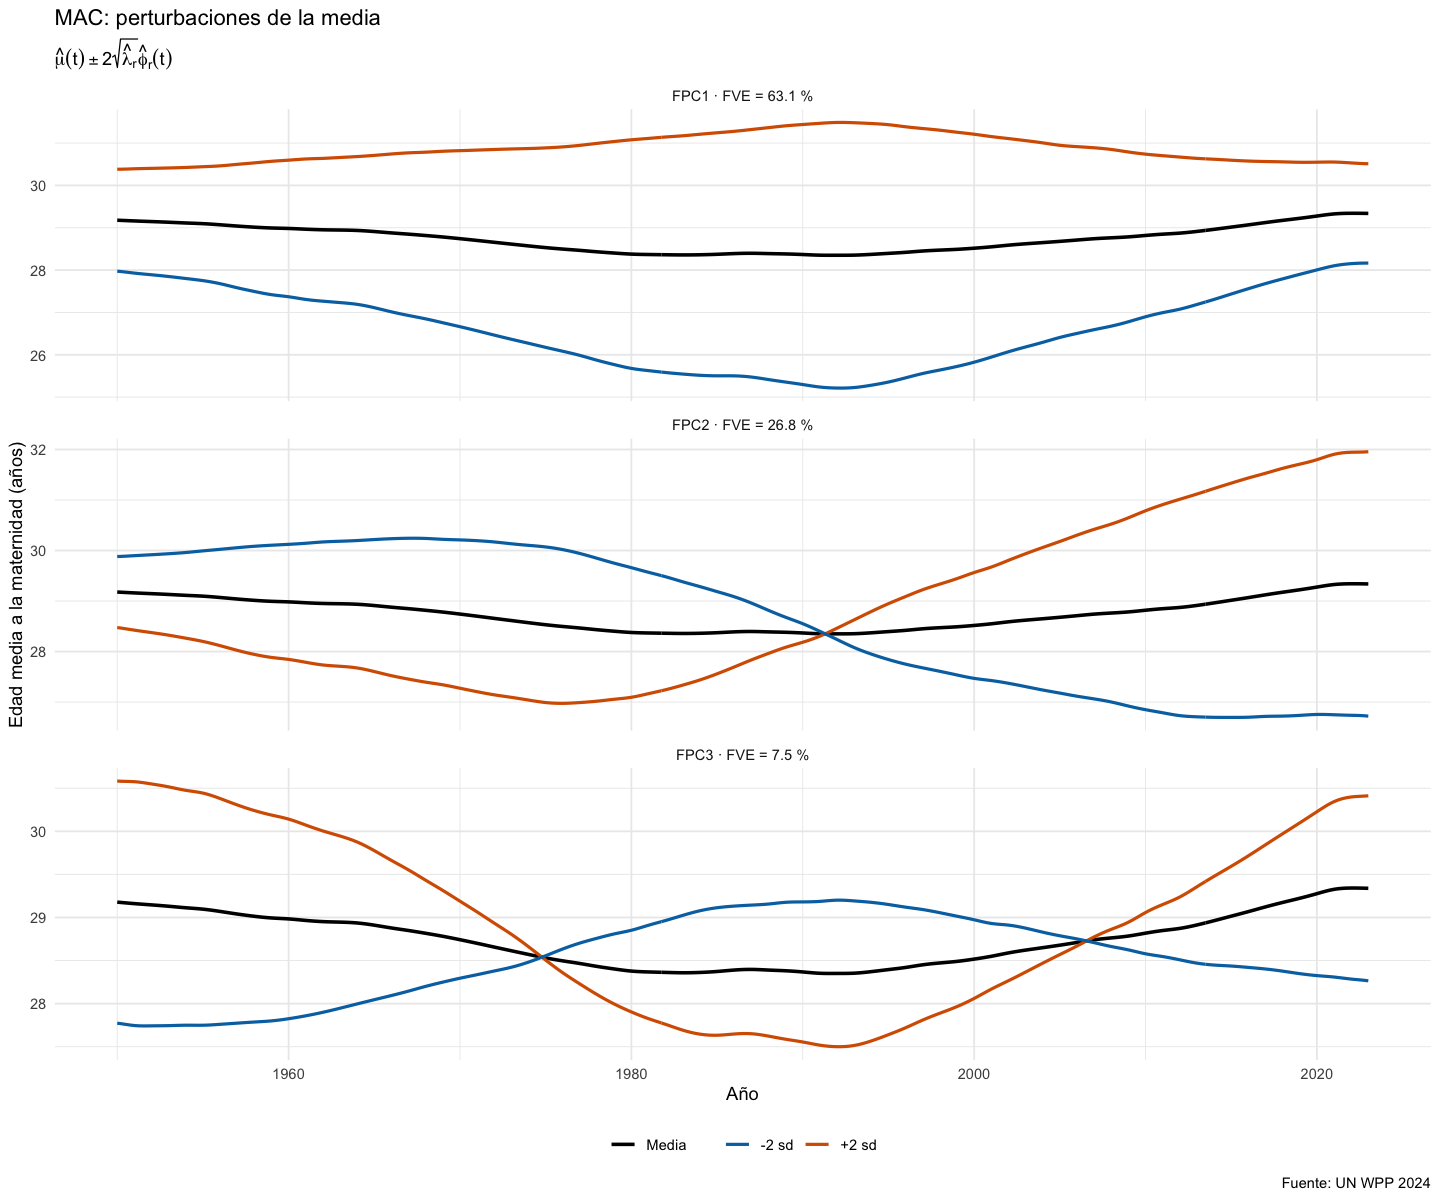

In [13]:
p1 <- fig_autofunciones(p, "MAC")
guardar_fig(p1, "fpca_MAC_autofunciones", w = 10, h = 5.5); print(p1)
options(repr.plot.height = 10)
p2 <- fig_perturbaciones(p, "MAC")
guardar_fig(p2, "fpca_MAC_perturbaciones", w = 9, h = 10); print(p2)
options(repr.plot.height = 7)


## MAC · 4. Scores
Se guardan los scores país × componente (FPC1–FPC10, con `ISO3_code`, `Location` y región) junto con los valores propios, las autofunciones y la media en `output/data/fpca_MAC.rds`. Se listan los cinco países con scores más extremos en FPC1 y FPC2 como apoyo a la interpretación.


In [14]:
sc <- tabla_scores(p)
stopifnot(nrow(sc) == 200, !anyNA(sc), abs(colMeans(p$scores)) < 1e-8 * max(abs(p$scores)))
saveRDS(list(indicador = "MAC", scores = sc, values = p$values, fve = p$values / sum(p$values),
             K90 = K90, K95 = K95, harmonics = p$harmonics, meanfd = p$meanfd, lambda_suav = fds[["MAC"]]$lambda),
        here::here("output/data/fpca_MAC.rds"))
extremos(sc, "FPC1"); extremos(sc, "FPC2")
sc |> group_by(region) |> summarise(n = n(), FPC1_media = mean(FPC1), FPC2_media = mean(FPC2), .groups = "drop") |>
  mutate(across(where(is.double), ~ round(.x, 2))) |> as.data.frame() |> print(row.names = FALSE)

fve <- p$values / sum(p$values)
resumen[["MAC"]] <- tibble(indicador = "MAC", FVE1 = fve[1], FVE2 = fve[2], FVE3 = fve[3], K90 = K90, K95 = K95)
fpc1[["MAC"]] <- setNames(sc$FPC1, sc$ISO3_code)


FPC1  más negativos: BGR, CUB, UKR, ROU, CZE
FPC1  más positivos: DJI, LBY, DZA, RWA, TLS
FPC2  más negativos: AZE, VNM, TJK, NPL, UZB
FPC2  más positivos: DNK, CZE, LUX, SWE, DEU
                          region  n FPC1_media FPC2_media
                          Africa 57       6.37      -1.21
                            Asia 51       2.11      -1.73
                          Europe 41      -6.25       6.30
 Latin America and the Caribbean 36      -6.40      -3.68
                Northern America  2      -8.46       8.90
                         Oceania 13       2.54       1.00


## MAC · 5. Interpretación
- **FPC1 (63.1 %): nivel de MAC, con su máximo de contraste en 1980–2000.** La autofunción es positiva en todo el período y llega a su pico hacia 1992.
  - Un score **positivo** corresponde a una MAC alta y estable, que es la de los países de fecundidad alta, donde los nacimientos de orden alto elevan la edad media: Yibuti, Libia, Argelia, Ruanda y Timor-Leste (media de África: +6.4).
  - Un score **negativo** describe una MAC que cae a ~25 años hacia 1990 y luego se recupera: Bulgaria, Cuba, Ucrania, Rumanía y Chequia, con maternidad temprana en el socialismo de Europa del Este.
- **FPC2 (26.8 %): *timing* del aplazamiento de la maternidad.** La autofunción cambia de signo hacia 1991.
  - Un score **positivo** describe una MAC que baja hasta ~1975 y luego sube con fuerza hasta ~32 años: el **aplazamiento** típico de Europa occidental y Northern America (Dinamarca, Chequia, Luxemburgo, Suecia, Alemania; medias de +6.3 y +8.9).
  - Un score **negativo** describe una MAC alta al inicio que cae de forma sostenida: países que *rejuvenecen* la maternidad al bajar la fecundidad y aún no la aplazan (Azerbaiyán, Vietnam, Tayikistán, Nepal, Uzbekistán).
- **FPC3 (7.5 %): curva en U frente a curva en U invertida.** Captura la forma completa de "caída y recuperación" de la MAC.
- Con $K_{90}=K_{95}=3$, MAC necesita tres componentes y su FVE1 es bajo (63 %): los países se diferencian sobre todo por la *forma* de su curva, no solo por el nivel. Esto confirma lo que se vio en F2.


# Indicador: MedianAgePop – Edad mediana de la población

## MedianAgePop · 1–2. FPCA y fracción de varianza explicada
FPCA centrado sobre el objeto `fd` de F3 (200 países, 76 funciones base) con `nharm = 10`. La tabla muestra los 10 primeros valores propios con su FVE individual y acumulado; $K_{90}$ y $K_{95}$ se calculan con el espectro completo.


In [15]:
p <- correr_fpca(fds[["MedianAgePop"]]$fd)
tab <- tabla_fve(p, "MedianAgePop")
guardar_tabla(tab, "fpca_fve_MedianAgePop")
tab |> mutate(valor_propio = signif(valor_propio, 4), across(c(FVE, FVE_acum), ~ round(100 * .x, 2))) |>
  rename(`FVE (%)` = FVE, `FVE acum (%)` = FVE_acum) |> as.data.frame() |> print(row.names = FALSE)
K90 <- K_fve(p, 0.90); K95 <- K_fve(p, 0.95)
cat(sprintf("\nK90 = %d | K95 = %d\n", K90, K95))


    indicador componente valor_propio FVE (%) FVE acum (%)
 MedianAgePop       FPC1    3204.0000   90.42        90.42
 MedianAgePop       FPC2     279.4000    7.89        98.31
 MedianAgePop       FPC3      32.1900    0.91        99.22
 MedianAgePop       FPC4      15.9100    0.45        99.67
 MedianAgePop       FPC5       3.9750    0.11        99.78
 MedianAgePop       FPC6       2.5070    0.07        99.85
 MedianAgePop       FPC7       1.8180    0.05        99.90
 MedianAgePop       FPC8       0.9247    0.03        99.93
 MedianAgePop       FPC9       0.6662    0.02        99.94
 MedianAgePop      FPC10       0.4924    0.01        99.96

K90 = 1 | K95 = 2


## MedianAgePop · 3. Autofunciones y perturbaciones de la media
La primera figura muestra las tres primeras autofunciones $\hat\phi_r(t)$. La segunda muestra, para cada componente, la media $\hat\mu(t)$ (negro) y las curvas $\hat\mu(t)\pm2\sqrt{\hat\lambda_r}\,\hat\phi_r(t)$: cómo se ve un país con score de $\pm2$ desviaciones estándar en esa componente y 0 en las demás.


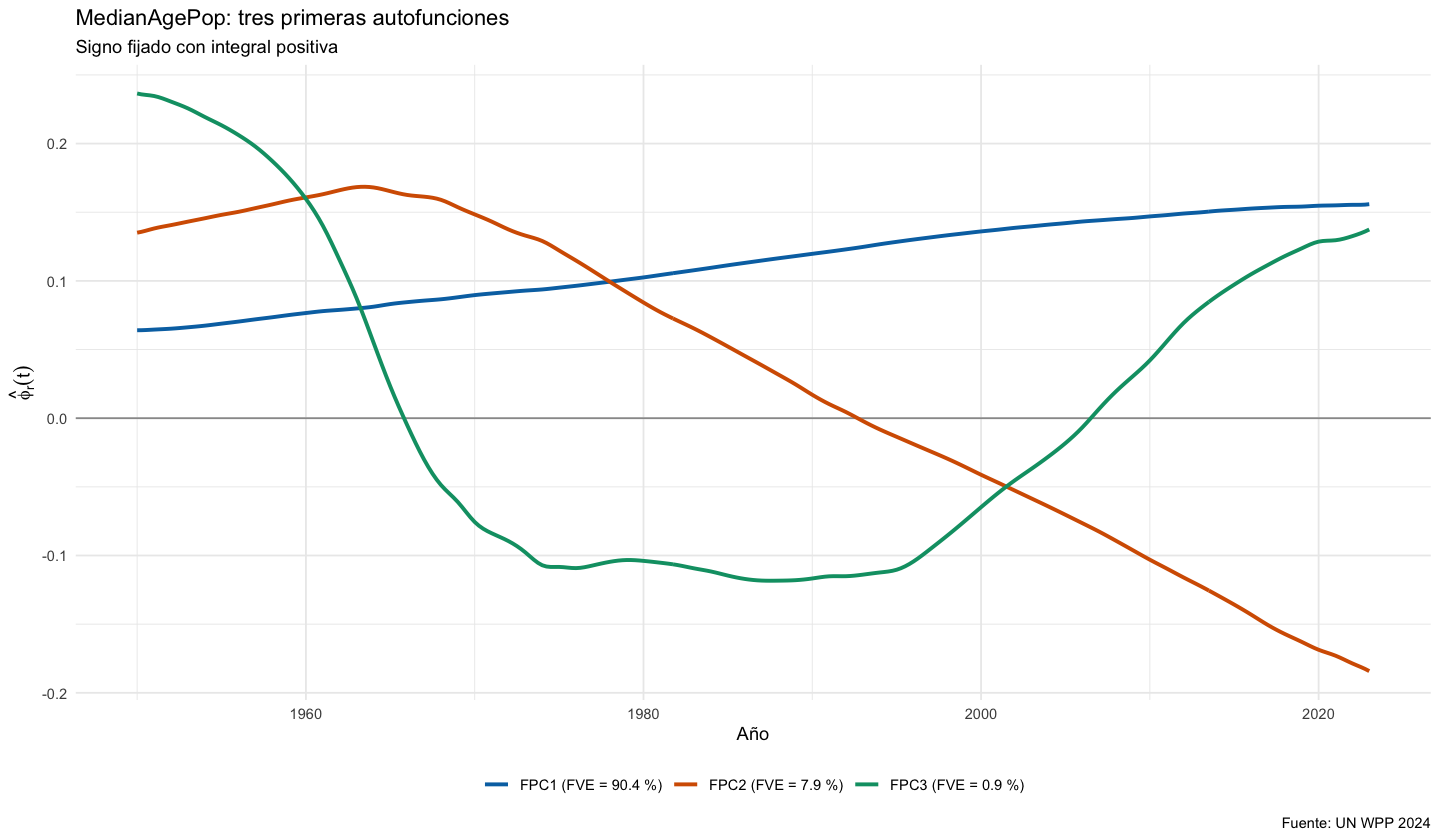

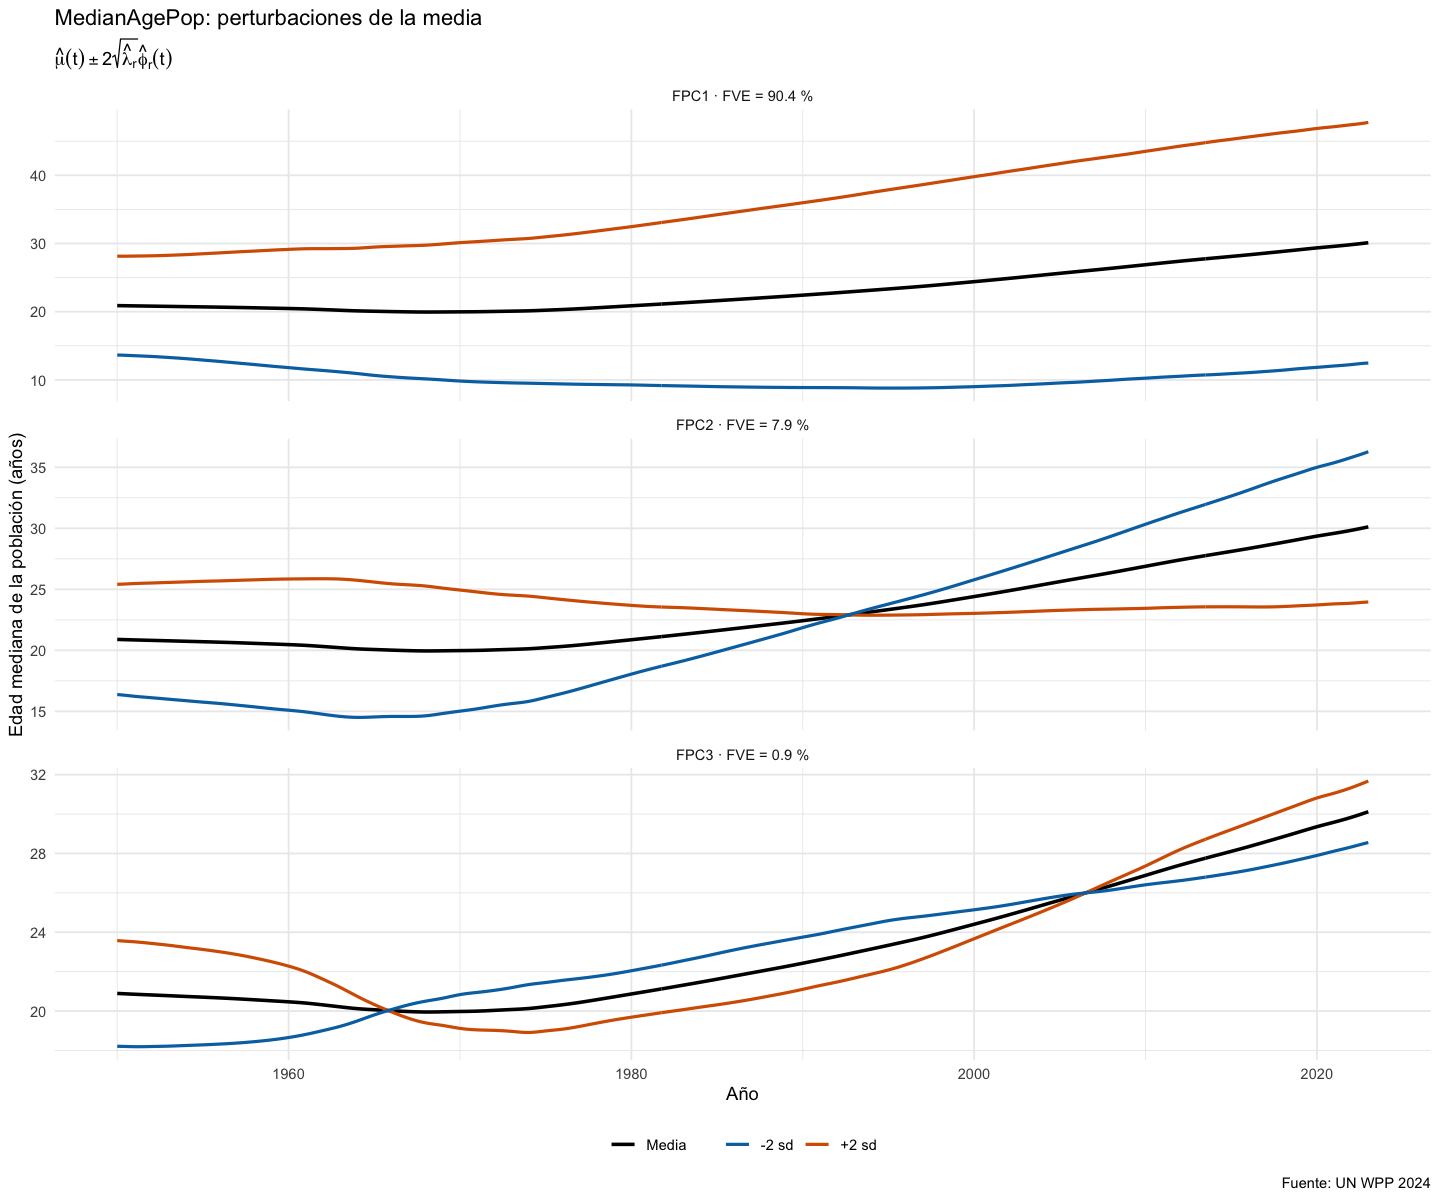

In [16]:
p1 <- fig_autofunciones(p, "MedianAgePop")
guardar_fig(p1, "fpca_MedianAgePop_autofunciones", w = 10, h = 5.5); print(p1)
options(repr.plot.height = 10)
p2 <- fig_perturbaciones(p, "MedianAgePop")
guardar_fig(p2, "fpca_MedianAgePop_perturbaciones", w = 9, h = 10); print(p2)
options(repr.plot.height = 7)


## MedianAgePop · 4. Scores
Se guardan los scores país × componente (FPC1–FPC10, con `ISO3_code`, `Location` y región) junto con los valores propios, las autofunciones y la media en `output/data/fpca_MedianAgePop.rds`. Se listan los cinco países con scores más extremos en FPC1 y FPC2 como apoyo a la interpretación.


In [17]:
sc <- tabla_scores(p)
stopifnot(nrow(sc) == 200, !anyNA(sc), abs(colMeans(p$scores)) < 1e-8 * max(abs(p$scores)))
saveRDS(list(indicador = "MedianAgePop", scores = sc, values = p$values, fve = p$values / sum(p$values),
             K90 = K90, K95 = K95, harmonics = p$harmonics, meanfd = p$meanfd, lambda_suav = fds[["MedianAgePop"]]$lambda),
        here::here("output/data/fpca_MedianAgePop.rds"))
extremos(sc, "FPC1"); extremos(sc, "FPC2")
sc |> group_by(region) |> summarise(n = n(), FPC1_media = mean(FPC1), FPC2_media = mean(FPC2), .groups = "drop") |>
  mutate(across(where(is.double), ~ round(.x, 2))) |> as.data.frame() |> print(row.names = FALSE)

fve <- p$values / sum(p$values)
resumen[["MedianAgePop"]] <- tibble(indicador = "MedianAgePop", FVE1 = fve[1], FVE2 = fve[2], FVE3 = fve[3], K90 = K90, K95 = K95)
fpc1[["MedianAgePop"]] <- setNames(sc$FPC1, sc$ISO3_code)


FPC1  más negativos: NER, UGA, ZMB, KEN, BDI
FPC1  más positivos: DEU, ITA, SWE, JPN, AUT
FPC2  más negativos: MTQ, GLP, TWN, KOR, THA
FPC2  más positivos: LUX, GAB, SWE, GBR, JEY
                          region  n FPC1_media FPC2_media
                          Africa 57     -49.48       7.88
                            Asia 51      -8.07      -6.43
                          Europe 41      84.64       9.88
 Latin America and the Caribbean 36      -4.33     -14.06
                Northern America  2      72.92       4.84
                         Oceania 13     -17.58      -2.29


## MedianAgePop · 5. Interpretación
- **FPC1 (90.4 %): grado de envejecimiento, que se amplía con el tiempo.** La autofunción es positiva y crece casi linealmente desde ~1970. Con +2 sd, la curva queda +7 años sobre la media en 1950 y +18 en 2023, que es la divergencia vista en F2. En el extremo positivo están Alemania, Italia, Suecia, Japón y Austria; en el negativo, Níger, Uganda, Zambia, Kenia y Burundi. Por región, Europa tiene media +84.6 y África −49.5.
- **FPC2 (7.9 %): *timing* y velocidad del envejecimiento.** La autofunción cambia de signo hacia 1993.
  - Un score **negativo** describe una población muy joven hacia 1965 que envejece rápido desde los 70 y supera la media en los 90: Martinica, Guadalupe, Taiwán, Corea del Sur y Tailandia. Es el **envejecimiento acelerado** (media de América Latina: −14.1).
  - Un score **positivo** describe una población relativamente envejecida ya en 1950 cuya edad mediana sube poco: Luxemburgo, Suecia, Reino Unido, Jersey y Gabón. Son los pioneros de la transición, más algunos casos con una estructura casi estancada.
- Con $K_{90}=1$ y $K_{95}=2$, es el indicador de menor dimensión: casi todo se resume en *cuánto* envejeció un país, más el *cuándo* de FPC2.


# Síntesis comparada

## 6. Tabla comparativa del FPCA
FVE de las tres primeras componentes y número de componentes necesarias para el 90 % y el 95 % de la varianza. Se guarda en `output/tables/fpca_resumen.csv` y `.tex`.


In [18]:
fpca_resumen <- bind_rows(resumen)
stopifnot(identical(fpca_resumen$indicador, IND))
guardar_tabla(fpca_resumen |> mutate(across(starts_with("FVE"), ~ round(.x, 4))), "fpca_resumen", tex = TRUE)
fpca_resumen |> mutate(across(starts_with("FVE"), ~ round(100 * .x, 1))) |>
  rename(`FVE1 (%)` = FVE1, `FVE2 (%)` = FVE2, `FVE3 (%)` = FVE3) |>
  as.data.frame() |> print(row.names = FALSE)


    indicador FVE1 (%) FVE2 (%) FVE3 (%) K90 K95
          TFR     85.1     11.1      2.1   2   2
          LEx     88.2      7.4      2.3   2   2
       CNMR_t     47.6     17.3      7.6   8  11
          MAC     63.1     26.8      7.5   3   3
 MedianAgePop     90.4      7.9      0.9   1   2


## 7. Correlación de Spearman entre los FPC1 de los indicadores
Se calcula la correlación de rangos $\rho_S$ entre los scores FPC1 de cada par de indicadores, con los mismos 200 países. Anticipa la pregunta 8: si los modos dominantes de los distintos indicadores están muy correlacionados, el MFPCA los combinará en una sola componente común, el "gradiente de desarrollo demográfico".

**Ojo con el signo:** depende de la convención $\int\hat\phi_1>0$, así que FPC1 alto significa nivel alto del indicador (más fecundidad, más esperanza de vida, más inmigración, etc.).


                TFR    LEx CNMR_t    MAC MedianAgePop
TFR           1.000 -0.892 -0.232  0.585       -0.976
LEx          -0.892  1.000  0.263 -0.434        0.885
CNMR_t       -0.232  0.263  1.000  0.121        0.323
MAC           0.585 -0.434  0.121  1.000       -0.520
MedianAgePop -0.976  0.885  0.323 -0.520        1.000


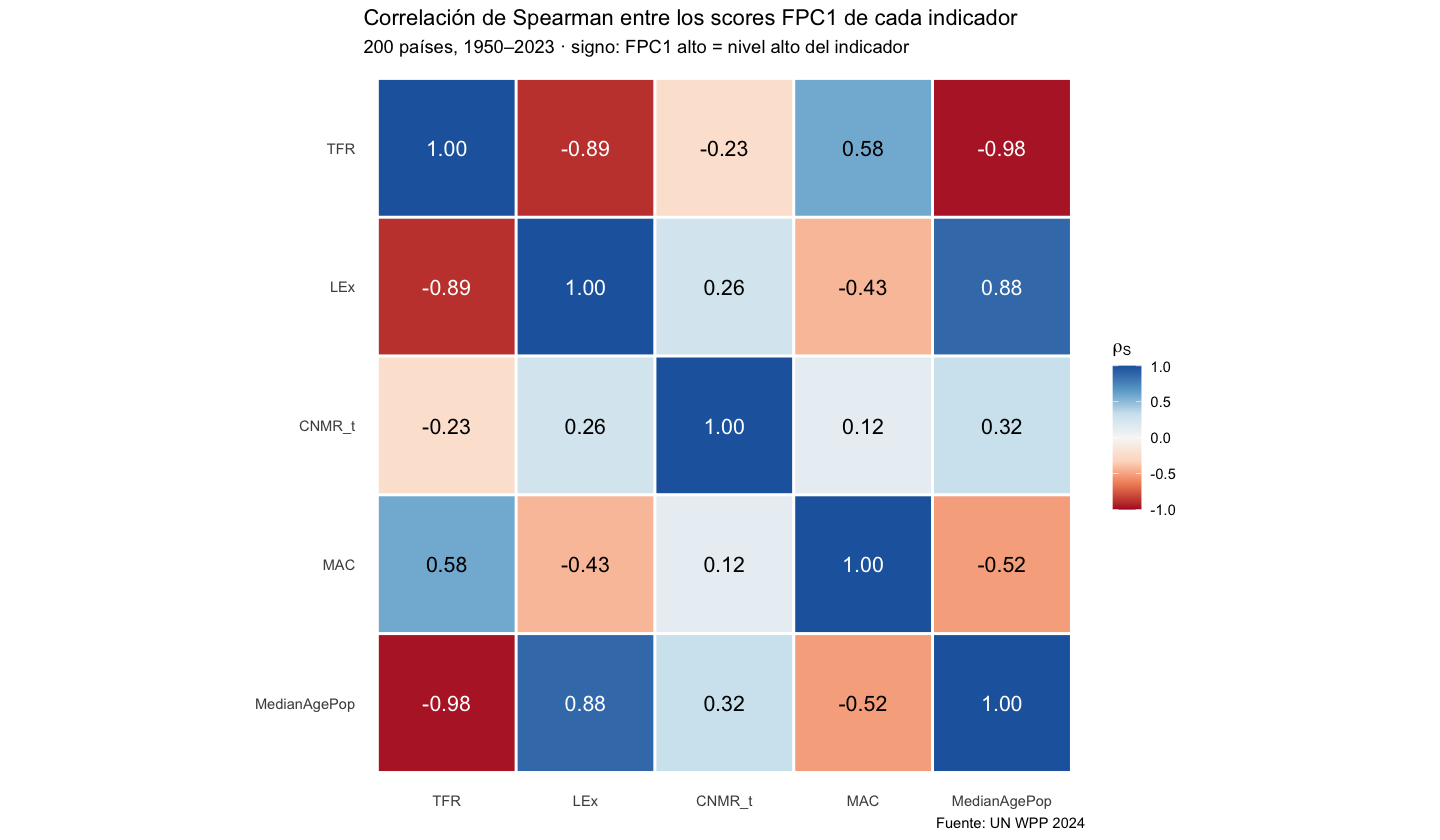

In [19]:
F1 <- bind_cols(fpc1)
stopifnot(nrow(F1) == 200, all(sapply(fpc1, \(x) identical(names(x), meta$ISO3_code))))
rho <- cor(F1, method = "spearman")
print(round(rho, 3))

d_rho <- as_tibble(rho, rownames = "fila") |> pivot_longer(-fila, names_to = "col", values_to = "rho") |>
  mutate(fila = factor(fila, levels = rev(IND)), col = factor(col, levels = IND))
p <- ggplot(d_rho, aes(col, fila, fill = rho)) +
  geom_tile(colour = "white", linewidth = 0.8) +
  geom_text(aes(label = sprintf("%.2f", rho), colour = abs(rho) > 0.6), size = 4.5, show.legend = FALSE) +
  scale_colour_manual(values = c(`TRUE` = "white", `FALSE` = "black")) +
  scale_fill_distiller(palette = "RdBu", limits = c(-1, 1), direction = 1, name = expression(rho[S])) +
  coord_equal() +
  labs(title = "Correlación de Spearman entre los scores FPC1 de cada indicador",
       subtitle = "200 países, 1950–2023 · signo: FPC1 alto = nivel alto del indicador",
       x = NULL, y = NULL, caption = "Fuente: UN WPP 2024") +
  theme_minimal(base_size = 11) + theme(panel.grid = element_blank())
guardar_fig(p, "fpca_spearman_FPC1", w = 8, h = 6.5); p


## 8. Conclusiones de F4

**Dimensión de cada indicador.**

| Indicador | FVE1 | FVE2 | FVE3 | K90 | K95 | FPC1 | FPC2 |
|---|---|---|---|---|---|---|---|
| TFR | 85.1 % | 11.1 % | 2.1 % | 2 | 2 | Nivel | Timing/velocidad de la caída |
| LEx | 88.2 % | 7.4 % | 2.3 % | 2 | 2 | Nivel | Ganancia rápida frente a estancamiento (VIH/sida) |
| CNMR_t | 47.6 % | 17.3 % | 7.6 % | 8 | 11 | Receptor frente a emisor | Reversión de régimen hacia 1990 |
| MAC | 63.1 % | 26.8 % | 7.5 % | 3 | 3 | Nivel (contraste 1980–2000) | Aplazamiento de la maternidad |
| MedianAgePop | 90.4 % | 7.9 % | 0.9 % | 1 | 2 | Grado de envejecimiento | Timing del envejecimiento |

- **TFR, LEx y MedianAgePop son casi bidimensionales:** un modo de *nivel* dominante (85–90 %) y un modo de *timing* (8–11 %) que cambia de signo entre 1983 y 1993. El segundo modo es justo la información de trayectoria que un corte transversal no captura.
- **MAC tiene un segundo modo fuerte** (26.8 %), el aplazamiento. Es el indicador donde la *forma* pesa más en relación con el nivel.
- **CNMR_t es de alta dimensión** ($K_{95}=11$): muchos episodios migratorios de importancia similar. Los 10 scores guardados explican el 94.0 %.

**Correlación entre los FPC1 (anticipo de la pregunta 8).** TFR, LEx y MedianAgePop forman un bloque casi colineal ($\rho_S$: TFR–MedianAgePop −0.98, TFR–LEx −0.89, LEx–MedianAgePop +0.89), que es el gradiente de la transición demográfica. MAC se asocia moderadamente con ese bloque (0.59 con TFR), y CNMR_t es casi independiente ($|\rho_S|\le0.32$), como se anticipó en el plan.

**Implicaciones para F5 (MFPCA):**
- Es de esperar que la primera componente multivariada combine los niveles de TFR, LEx y MedianAgePop y explique una fracción grande de la varianza.
- Los grupos por trayectoria se distinguirán sobre todo en las componentes siguientes, que mezclan los modos de timing (FPC2 de TFR, LEx, MAC y MedianAgePop) y la migración.
- Por su espectro plano, CNMR_t aportará varias componentes de baja varianza. Con la normalización de Chiou, su peso dependerá de $\hat v(t)$, lo que hay que vigilar en la selección de $L$ por FVE.

**Notas técnicas.**
- La ortonormalidad de las autofunciones se verificó con tolerancia $10^{-3}$, por la cuadratura numérica de `inprod`. Los errores observados son de ~$5\cdot10^{-4}$.
- Los scores tienen media cero por construcción, lo que también se verificó.
